#### Notebook for comparing the cnoidal waves with the waves from the Newton solver

In [13]:
import sys
from pathlib import Path

root = Path.cwd().parent
sys.path.insert(0,str(root))

In [14]:
from camera.camera_file import Camera
from camera.spectralCamera import KdVNewton
from camera.pdeCamera import KdV
from solvers.help import *
from waves.soliton import kdv_cnoidal


import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt

In [15]:
# Wave parameters

N = 2**6
amp = 1
mean = 0
P = 4
c1 = Camera(P,N,1)

In [16]:
#Creating a newton wave
wp = KdVNewton(P,amp, mean, c1)
wp.solve_w_continuation()
phi_newton = wp.get_physical(wp.phi_hat_mid)

In [17]:
# then the cnoidal wave

phi_cn, c_cn, m = kdv_cnoidal(
    P = wp.P,
    crest=amp, 
    mean = mean,
    x = c1.x,
    t=0
)

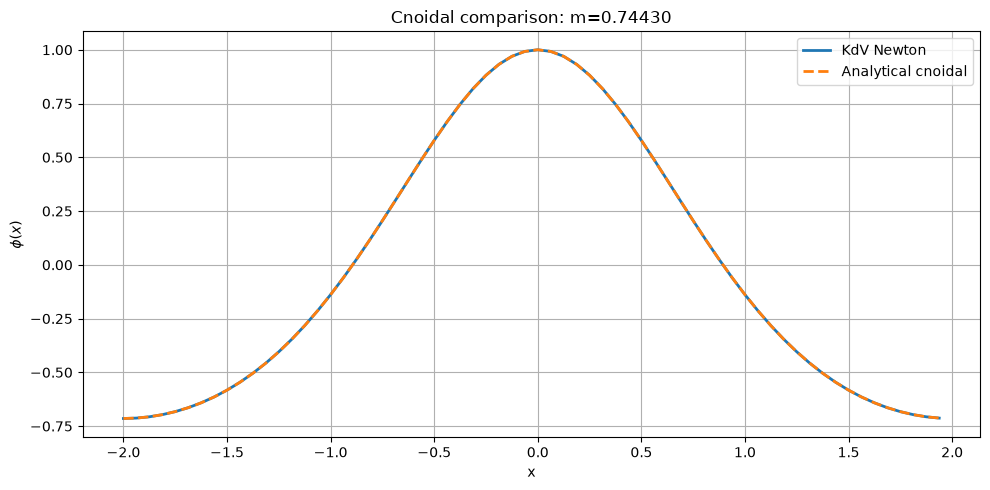

Newton wave speed:    0.6606338967
Cnoidal wave speed:   0.6606338967
Maximum profile error: 8.882e-16
RMS profile error:     3.435e-16


In [18]:
# Plotting them
plt.figure(figsize=(10, 5))
plt.plot(c1.x, phi_newton, label="KdV Newton", linewidth=2)
plt.plot(c1.x, phi_cn[0], "--", label="Analytical cnoidal", linewidth=2)
plt.xlabel("x")
plt.ylabel(r"$\phi(x)$")
plt.title(f"Cnoidal comparison: m={m:.5f}")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Newton wave speed:    {wp.c:.10f}")
print(f"Cnoidal wave speed:   {c_cn:.10f}")
print(f"Maximum profile error: "
      f"{np.max(np.abs(phi_newton - phi_cn)):.3e}")
print(f"RMS profile error:     "
      f"{np.sqrt(np.mean((phi_newton - phi_cn)**2)):.3e}")

We can then look at the forward solver and compare it to the analytical cnoidal wave

In [19]:
# Wave parameters
N = 2**6
L = 4
dt = 5e-3

c2 = Camera(L,N,dt)

T = 1
amp = 1
mean = 0

In [ ]:
# Newton wave and solver
nw = KdVNewton(P,amp,mean,c2)
nw.solve_w_continuation()
nw_phi = nw.get_physical(nw.phi_hat_mid)

ns = KdV(c2, T, u0=nw_phi)
t,ns_phi = ns.ifrk4()

In [21]:
# Cnoidal wave
cn_phi, c_cn, m = kdv_cnoidal(P, amp, mean,c2.x,t)

In [22]:
animate_solution_nb(c2.x, ns_phi)

In [23]:
animate_solution_nb(c2.x, cn_phi)

In [24]:
animate_solution_nb(c2.x, ns_phi - ns_phi)

As we can see from the plots, the numerical solver and the analytical cn wave give the same answers in the time steps looked at. 